In [74]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, firwin

## 2.RLS algorithm implementation and validation :

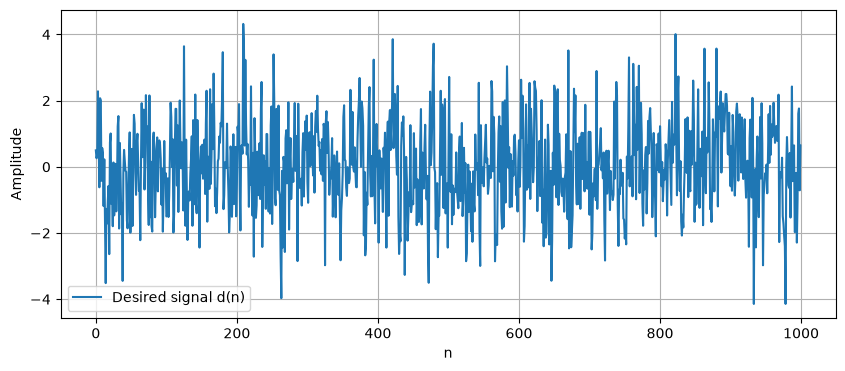

In [75]:
#ToDo 2:
np.random.seed(42) # le 42 veut dire

N = 1000
h = np.array([1, 0.8, -0.3, 0.4])

x = np.random.randn(N)
d = lfilter(h, [1], x)

M = len(h)

plt.figure(figsize=(10, 4))
plt.plot(d, label="Desired signal d(n)")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()


In [76]:
#ToDO 3:
def algoRLS(x,d,M,lambd):
    N=len(x)
    #initialize w
    w=np.zeros(M)

    #initialize S
    sigma=0.001
    S=np.eye(M)/sigma

    w_history = np.zeros((N, M)) #store the weights
    y = np.zeros(N)
    e = np.zeros(N)

    for n in range(M-1,N):
        
        X = x[n-M+1:n+1][::-1]

        y[n]=np.dot(w,X)
        e[n]=y[n]-d[n]

        sn=(S @ X)/(lambd + X.T @ S @ X)
        w=w-sn*e[n]            

        S=(S-np.outer(sn,X.T@S))/lambd 

        w_history[n]=w

    return w_history, y, e



In [77]:
#ToDO 4:
m=4
lambd=0.1

w_history, y, e = algoRLS(x, d, m, lambd)

print("True coefficients:", h)
print("Estimated coefficients:", w_history[-1])


True coefficients: [ 1.   0.8 -0.3  0.4]
Estimated coefficients: [ 1.   0.8 -0.3  0.4]


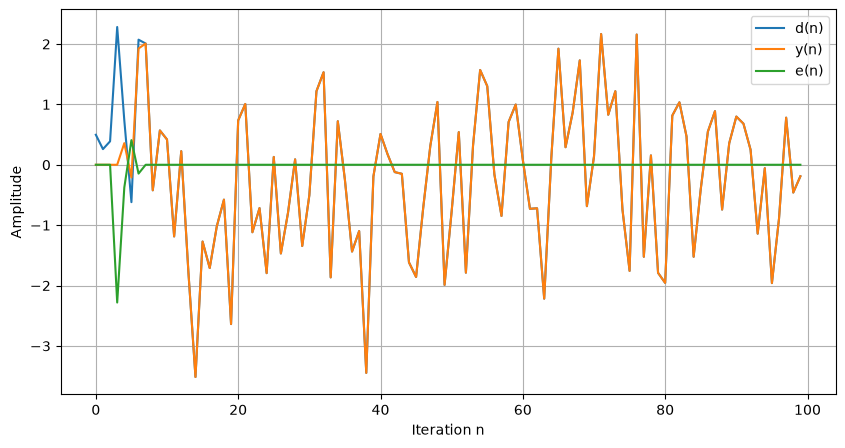

In [78]:
# plot dn, yn and en

plt.figure(figsize=(10, 5))

plt.plot(d[:100], label="d(n)")
plt.plot(y[:100], label="y(n)")
plt.plot(e[:100], label="e(n)")

plt.xlabel("Iteration n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()


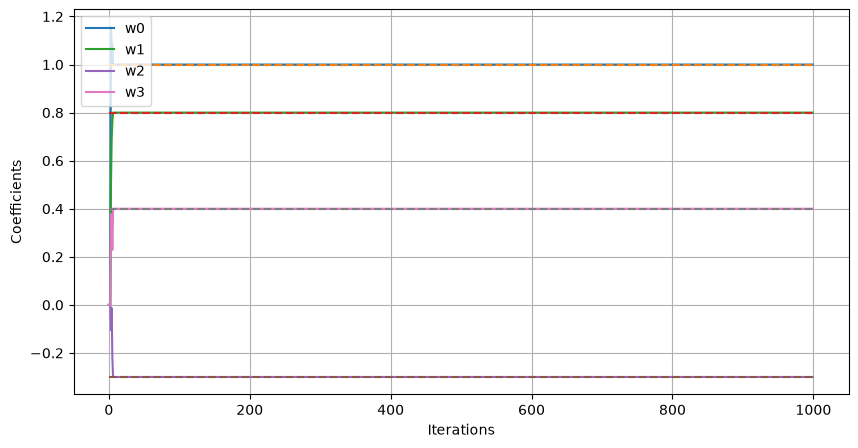

In [79]:
# plot Plot w opt, w(k)
plt.figure(figsize=(10,5))

for i in range(m):
    plt.plot(w_history[:,i], label="w"+str(i))
    plt.plot([0,len(x)], [h[i],h[i]], '--')

plt.xlabel("Iterations")
plt.ylabel("Coefficients")
plt.legend()
plt.grid()
plt.show()

W0 converge to 1

W1 converge 0.8

W2 converge to -0.3

W3 convegre to 0.4

### checkpoint 1

In [80]:
#Todo5:
N = 1000
f = 0.5
P = [5, 10, 15]

np.random.seed(42)
x = np.random.randn(N)

sigma = 0.001
v = sigma* np.random.randn(N) #noise added

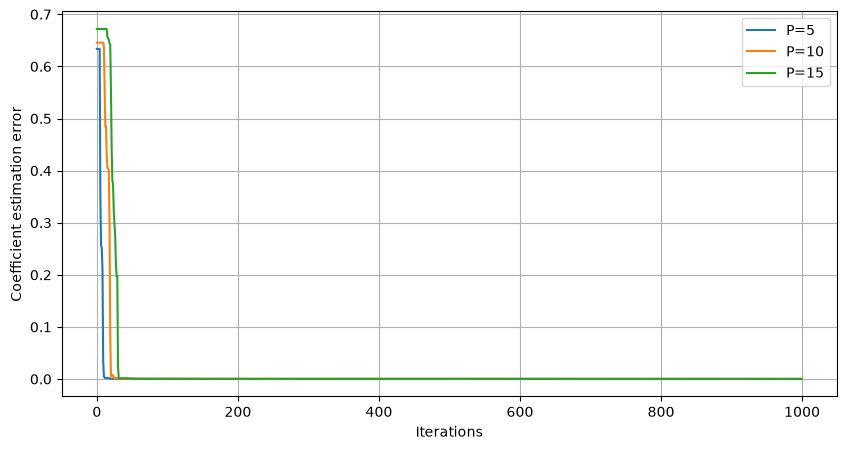

In [88]:
#Impact of P
lambd = 0.99

plt.figure(figsize=(10,5))

for p in P:
    h = firwin(p+1, f)
    d = lfilter(h, [1], x) + v # we generate d(n) with the filtre,  x(n), we add  v(n).
    w_history, y, e = algoRLS(x, d, p+1, lambd) #apply the RLS algo

    error = np.linalg.norm(w_history - h, axis=1) #we compare w with h
    plt.plot(error, label="P="+str(p))

plt.xlabel("Iterations")
plt.ylabel("Coefficient estimation error")
plt.legend()
plt.grid()
plt.show()

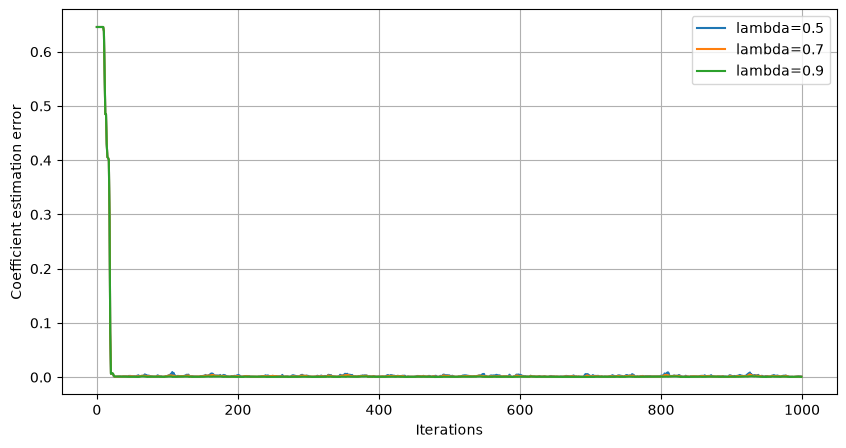

In [82]:
# impact of lambda
p = 10
h = firwin(p+1, f)
d = lfilter(h, [1], x) + v

plt.figure(figsize=(10,5))

for lambd in [0.5, 0.7, 0.9]:
    w_history, y, e = algoRLS(x, d, p+1, lambd)

    error = np.linalg.norm(w_history - h, axis=1)
    plt.plot(error, label="lambda="+str(lambd))

plt.xlabel("Iterations")
plt.ylabel("Coefficient estimation error")
plt.legend()
plt.grid()
plt.show()

In [83]:
#LMS
def algoLMS(x,d,M, mu):
    N = len(x)
    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N) 
    
    for k in range(M, N):
        x_k = x[k:k-M:-1]  #Input vector
        y[k] = np.dot(w, x_k)
        e[k] = d[k] - y[k]  #Error 
        w = w+mu*e[k]*x_k  #Update weights
    
    return y, e, w

#print(algoLMS(white_noise, d, 4, 0.01))

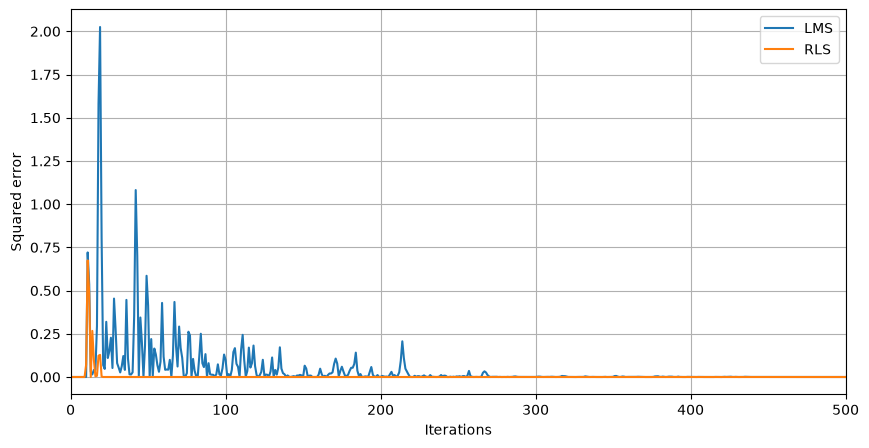

In [84]:
#LMS VS RLS

p = 10
h = firwin(p+1, f)
d = lfilter(h, [1], x) + v

mu = 0.01
lambd = 0.99

y_LMS, e_LMS, w_LMS = algoLMS(x, d, p+1, mu)
w_RLS, y_RLS, e_RLS = algoRLS(x, d, p+1, lambd)

plt.figure(figsize=(10,5))

plt.plot(e_LMS**2, label="LMS")
plt.plot(e_RLS**2, label="RLS")

plt.xlim(0, 500)
plt.xlabel("Iterations")
plt.ylabel("Squared error")
plt.legend()
plt.grid()
plt.show()


##### complexity :

RLS : O($M^2$)

LMS: O($M$)

### checkpoint 3

## 3. Audio Application :

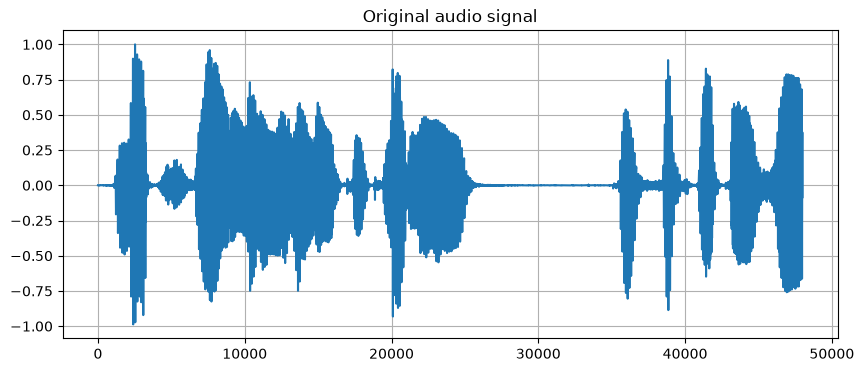

In [94]:
#Todo 6:

import librosa
from IPython.display import Audio, display
#original audio
s, Fs = librosa.load("dataTP2/Voix1.wav", sr=None)

# First 3 seconds
s = s[:3*Fs]
N = len(s)

plt.figure(figsize=(10,4))
plt.plot(s)
plt.title("Original audio signal")
plt.grid()
plt.show()

display(Audio(s, rate=Fs))

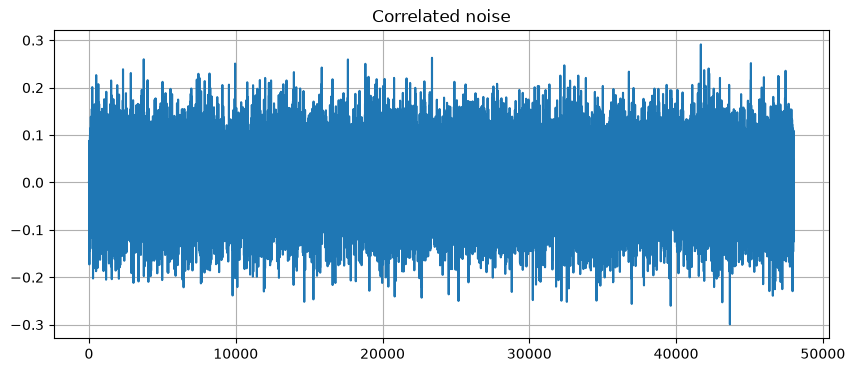

In [95]:
#whiye noise
np.random.seed(42)

sigma = 0.1
b = sigma * np.random.randn(N)

h = firwin(33, 0.5)
noise = lfilter(h, [1], b)

plt.figure(figsize=(10,4))
plt.plot(noise)
plt.title("Correlated noise")
plt.grid()
plt.show()


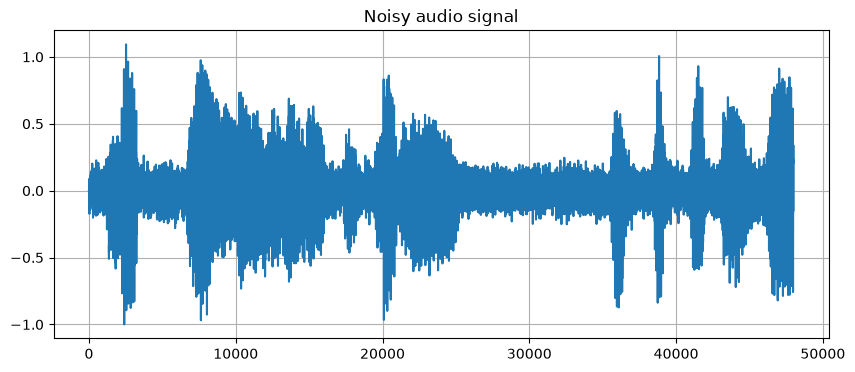

In [96]:
#noise + audio
d = s + noise

plt.figure(figsize=(10,4))
plt.plot(d)
plt.title("Noisy audio signal")
plt.grid()
plt.show()

display(Audio(d, rate=Fs))


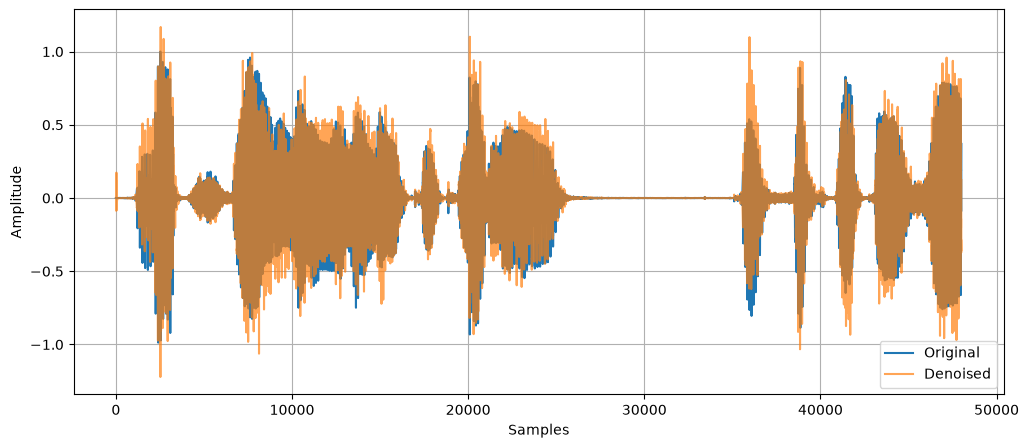

In [97]:
# RLS
m = 33
lambd = 0.99

w_history, y, e = algoRLS(b, d, m, lambd)

s_est = y - d

plt.figure(figsize=(12,5))

plt.plot(s, label="Original")
plt.plot(s_est, label="Denoised", alpha=0.7)

plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

display(Audio(s_est, rate=Fs))
